# Model Evaluation and Multimodal Logic

This notebook evaluates the three models used by the system and then tests the **combined** decision logic
(face check -> product model -> voice check). 

| Model | Owner | What is reported here |
|-------|-------|-----------------------|
| Facial recognition (YuNet + SFace embeddings + logistic regression) | David | leave-one-image-out accuracy, F1, log loss, false-accept and false-reject rates, stranger rejection, robustness |
| Voiceprint verification (MFCC features + Random Forest) | Nazira | member acceptance, unknown-voice rejection |
| Product recommendation (Random Forest) | Shamila | accuracy, F1, log loss (from `data_merge.ipynb`) |
| Combined system | Allan | authorized pass rate and false-accept rate over 20 transactions |

## 1. Setup

In [ ]:
import sys, shutil, tempfile, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import facial_recognition as fr
import voice_verification as vv
import system_integration as si

MEMBERS = ["Allan", "David", "Nazira", "Shamila"]
TMP = Path(tempfile.mkdtemp())          # altered test photos go here; the team's saved models and data are never overwritten
pd.set_option("display.precision", 3)
print("Project root:", ROOT)
print("Component status:", si.component_status())

## 2. Facial recognition model

The face model detects the largest face (YuNet), aligns it, turns it into a 128-number embedding (SFace) and uses a logistic regression
to name the member. A face is **accepted only if its cosine similarity to that member's enrolled photos reaches the threshold**
(`DEFAULT_SIMILARITY_THRESHOLD`), so a stranger is rejected even though the classifier always picks one of the four members.

`evaluate_face_model()` (David's code) evaluates without leakage:
- **Identification:** each of the 12 original photos is predicted by a model trained on the *other* 11 photos and their augmentations.
- **Impostors:** each member is removed from training in turn and their photos shown as strangers, plus every image in `datasets/unauthorized_images/`.

In [2]:
images = fr.discover_images()
feature_table, feature_names = fr.build_feature_table(images)
evaluation = fr.evaluate_face_model(feature_table, feature_names, fr.discover_unauthorized_images())
print(f"Photos: {len(images)}   feature table: {feature_table.shape[0]} rows (photo x augmentation), {len(feature_names)} embedding values each")
pd.Series(evaluation["metrics"], name="face model, leave-one-image-out").to_frame()

Photos: 12   feature table: 60 rows (photo x augmentation), 128 embedding values each


,"face model, leave-one-image-out"
accuracy,1.000
precision_macro,1.000
recall_macro,1.000
f1_macro,1.000
log_loss,0.173
false_reject_rate,0.000
false_accept_rate,0.000
verification_accuracy,1.000


In [3]:
classes = evaluation["classes"]
pd.DataFrame(evaluation["confusion_matrix"], index=[f"true {c}" for c in classes], columns=[f"predicted {c}" for c in classes])

,predicted Allan,predicted David,predicted Nazira,predicted Shamila
true Allan,3,0,0,0
true David,0,3,0,0
true Nazira,0,0,3,0
true Shamila,0,0,0,3


### 2.1 Is there a clear gap between members and strangers?

For a genuine photo we use its similarity to the claimed member's other photos; for an impostor, its best similarity to the member the model guessed.
A safe threshold must sit in the gap between the two groups.

In [4]:
genuine = np.array(evaluation["genuine_scores"])
impostors = evaluation["impostor_attempts"]
threshold = evaluation["threshold"]
print(f"Threshold                         : {threshold}")
print(f"Genuine photos   (n={len(genuine):2d})        : similarity {genuine.min():.3f} to {genuine.max():.3f}  (mean {genuine.mean():.3f})")
print(f"Impostor attempts (n={len(impostors):2d})        : similarity {impostors.similarity.min():.3f} to {impostors.similarity.max():.3f}  (mean {impostors.similarity.mean():.3f})")
print(f"Gap between the groups            : {genuine.min() - impostors.similarity.max():.3f}")
print(f"Impostors wrongly accepted        : {int(impostors.authorized.sum())}/{len(impostors)}")
print(f"Genuine photos wrongly rejected   : {int((genuine < threshold).sum())}/{len(genuine)}")
impostors.assign(probe=impostors.probe.str.replace("datasets/", "", regex=False))[["probe", "type", "similarity", "authorized"]]

Threshold                         : 0.45
Genuine photos   (n=12)        : similarity 0.574 to 0.894  (mean 0.723)
Impostor attempts (n=13)        : similarity 0.216 to 0.394  (mean 0.327)
Gap between the groups            : 0.179
Impostors wrongly accepted        : 0/13
Genuine photos wrongly rejected   : 0/12


,probe,type,similarity,authorized
0,images/Allan/Allan_neutral.jpg,held-out member,0.308,False
1,images/Allan/Allan_smiling.jpg,held-out member,0.394,False
2,images/Allan/Allan_surprised.jpg,held-out member,0.367,False
3,images/David/David_neutral.JPG,held-out member,0.358,False
4,images/David/David_smiling.JPG,held-out member,0.383,False
5,images/David/David_surprised.HEIC,held-out member,0.321,False
6,images/Nazira/Nazira_neutral.HEIC,held-out member,0.340,False
7,images/Nazira/Nazira_smiling.HEIC,held-out member,0.355,False
8,images/Nazira/Nazira_surprised.jpeg,held-out member,0.302,False
9,images/Shamila/Shamila_neutral.jpeg,held-out member,0.324,False


### 2.2 How robust is the saved face model to changes in a photo?

We take one neutral photo per member, alter it in ways that happen in real use (lighting, blur, cropping, resolution, head tilt)
and check the **saved** model (`models/face_model.pkl`). Altered copies are written to a temporary folder only.

In [5]:
from PIL import Image, ImageEnhance, ImageFilter, ImageOps

def variants(im):
    w, h = im.size
    yield "original", im
    yield "darker (0.75)", ImageEnhance.Brightness(im).enhance(0.75)
    yield "brighter (1.3)", ImageEnhance.Brightness(im).enhance(1.3)
    yield "head tilt (+12 deg)", im.rotate(12, fillcolor=(127, 127, 127))
    yield "blurred", im.filter(ImageFilter.GaussianBlur(1.5))
    yield "cropped 90%", im.crop((int(w * .05), int(h * .05), int(w * .95), int(h * .95)))
    yield "half resolution", im.resize((w // 2, h // 2))

neutral = {"Allan": "Allan/Allan_neutral.jpg", "David": "David/David_neutral.JPG",
           "Nazira": "Nazira/Nazira_neutral.HEIC", "Shamila": "Shamila/Shamila_neutral.jpeg"}
rows = []
for member, rel in neutral.items():
    img = ImageOps.exif_transpose(Image.open(fr.IMAGE_DIR / rel)).convert("RGB")
    for k, (name, variant) in enumerate(variants(img)):
        path = TMP / f"{member}_{k}.jpg"
        variant.save(path, quality=92)
        r = fr.verify_face(path)
        rows.append({"member": member, "variation": name, "similarity": r["similarity"],
                     "accepted_as_right_member": bool(r["authorized"] and r["identity"] == member)})
robust = pd.DataFrame(rows)
summary = robust.groupby("variation", sort=False).agg(accepted=("accepted_as_right_member", "sum"), of=("accepted_as_right_member", "size"),
                                                       mean_similarity=("similarity", "mean"), min_similarity=("similarity", "min"))
altered = robust[robust.variation != "original"]
print(f"Altered copies accepted as the right member: {int(altered.accepted_as_right_member.sum())}/{len(altered)}")
summary

Altered copies accepted as the right member: 24/24


,accepted,of,mean_similarity,min_similarity
variation,,,,
original,4,4,0.998,0.997
darker (0.75),4,4,0.985,0.976
brighter (1.3),4,4,0.989,0.981
head tilt (+12 deg),4,4,0.972,0.946
blurred,4,4,0.970,0.946
cropped 90%,4,4,0.971,0.956
half resolution,4,4,0.966,0.951


## 3. Voiceprint verification model

All recordings in `datasets/audio/` are passed through `verify_voice()` (the saved model, the same code the CLI uses).
Files named `unknown_*` are voices of a person outside the group and must be rejected.

Metrics from Nazira's training notebook (`audio_preprocessing.ipynb`), for reference:

| Test | Accuracy | F1 | Log loss |
|------|----------|----|----------|
| Held-out samples (14) | 1.000 | 1.000 | 0.246 |
| Unseen phrase (harder test) | 0.857 | 0.857 | 0.654 |

In [6]:
rows = []
for wav in sorted((ROOT / "datasets" / "audio").glob("*.wav")):
    r = vv.verify_voice(str(wav))
    owner = wav.stem.split("_")[0].lower()
    rows.append({"file": wav.name, "true_speaker": owner, "predicted": r["identity"], "confidence": r["confidence"], "accepted": r["verified"]})
voice_df = pd.DataFrame(rows)
members_v = voice_df[voice_df.true_speaker != "unknown"]
unknown_v = voice_df[voice_df.true_speaker == "unknown"]
print(f"Member recordings accepted with the right identity: {int(((members_v.accepted) & (members_v.predicted == members_v.true_speaker)).sum())}/{len(members_v)}")
print(f"Unknown-speaker recordings wrongly accepted: {int(unknown_v.accepted.sum())}/{len(unknown_v)}")
print(f"Lowest member confidence: {members_v.confidence.min():.3f}   highest unknown confidence: {unknown_v.confidence.max():.3f}")
voice_df

Member recordings accepted with the right identity: 8/8
Unknown-speaker recordings wrongly accepted: 0/2
Lowest member confidence: 0.965   highest unknown confidence: 0.475


,file,true_speaker,predicted,confidence,accepted
0,Allan_approve.wav,allan,allan,0.985,True
1,Allan_confirm.wav,allan,allan,0.975,True
2,David_approve.wav,david,david,0.965,True
3,David_confirm.wav,david,david,0.975,True
4,Nazira_approve.wav,nazira,nazira,0.970,True
5,Nazira_confirm.wav,nazira,nazira,0.970,True
6,Shamila_approve.wav,shamila,shamila,0.985,True
7,Shamila_confirm.wav,shamila,shamila,0.990,True
8,unknown_approve.wav,unknown,unknown,0.410,False
9,unknown_confirm.wav,unknown,unknown,0.475,False


## 4. Product recommendation model

These figures are quoted from `data_merge.ipynb` (Shamila), section 8, evaluated on her held-out customers:

| Metric | Value |
|--------|-------|
| Accuracy | 0.1613 |
| Precision (weighted) | 0.2419 |
| Recall (weighted) | 0.1613 |
| F1-score (weighted) | 0.1352 |
| Log loss | 1.7599 |
| Baseline accuracy (always predict the most common category) | 0.1613 |



In [7]:
import product_recommendation as pr
rows = []
for who, cid in si.load_identity_map().items():
    rows.append({"member": who, "customer_id": cid, "predicted_product": pr.predict_product(cid)})
pd.DataFrame(rows)

,member,customer_id,predicted_product
0,allan,151,Sports
1,david,192,Electronics
2,nazira,114,Sports
3,shamila,100,Electronics


## 5. Multimodal decision logic: the whole system

The system grants access only if **both** checks pass **and** they identify the **same person**. We test every combination of
a member's face (neutral photo) with every member's voice ("Confirm transaction") plus the unknown speaker: 4 x 5 = 20 transactions.
Only the 4 matching pairs should be granted.

In [8]:
comps = si.load_components(allow_mock=False)
system = si.SecureRecommendationSystem(comps.face_fn, comps.voice_fn, comps.product_fn)

face_files = {m.lower(): fr.IMAGE_DIR / rel for m, rel in neutral.items()}
voice_files = {m: ROOT / f"datasets/audio/{m.capitalize()}_confirm.wav" for m in face_files}
voice_files["unknown"] = ROOT / "datasets/audio/unknown_confirm.wav"

rows = []
for face_owner, face in face_files.items():
    for voice_owner, voice in voice_files.items():
        r = system.run_transaction(face, voice)
        rows.append({"face_of": face_owner, "voice_of": voice_owner, "status": r.status, "granted": r.granted})
matrix = pd.DataFrame(rows)
matrix["should_grant"] = matrix.face_of == matrix.voice_of
matrix["correct"] = matrix.granted == matrix.should_grant

authorized = matrix[matrix.should_grant]
impostor = matrix[~matrix.should_grant]
print(f"Transactions tested        : {len(matrix)}")
print(f"Authorized granted         : {int(authorized.granted.sum())}/{len(authorized)}")
print(f"Impostor attempts denied   : {int((~impostor.granted).sum())}/{len(impostor)}")
print(f"False-accept rate          : {impostor.granted.mean():.1%}")
print(f"False-reject rate          : {(~authorized.granted).mean():.1%}")
matrix.pivot(index="face_of", columns="voice_of", values="status")

Transactions tested        : 20
Authorized granted         : 4/4
Impostor attempts denied   : 16/16
False-accept rate          : 0.0%
False-reject rate          : 0.0%


voice_of,allan,david,nazira,shamila,unknown
face_of,,,,,
allan,GRANTED,DENIED_VOICE,DENIED_VOICE,DENIED_VOICE,DENIED_VOICE
david,DENIED_VOICE,GRANTED,DENIED_VOICE,DENIED_VOICE,DENIED_VOICE
nazira,DENIED_VOICE,DENIED_VOICE,GRANTED,DENIED_VOICE,DENIED_VOICE
shamila,DENIED_VOICE,DENIED_VOICE,DENIED_VOICE,GRANTED,DENIED_VOICE


### 5.1 A stranger's photo against the whole system

The stranger photos in `datasets/unauthorized_images/` are tried with each member's genuine voice. The face check must stop every one of them
before the voice is even requested.

In [9]:
rows = []
for photo in fr.discover_unauthorized_images():
    for voice_owner in face_files:
        r = system.run_transaction(photo, voice_files[voice_owner])
        rows.append({"photo": photo.name, "voice_of": voice_owner, "status": r.status})
stranger_matrix = pd.DataFrame(rows)
print(stranger_matrix.status.value_counts().to_string())
stranger_matrix

status
DENIED_FACE    4


,photo,voice_of,status
0,unknown_astronaut.png,allan,DENIED_FACE
1,unknown_astronaut.png,david,DENIED_FACE
2,unknown_astronaut.png,nazira,DENIED_FACE
3,unknown_astronaut.png,shamila,DENIED_FACE


### 5.2 Where members and strangers score

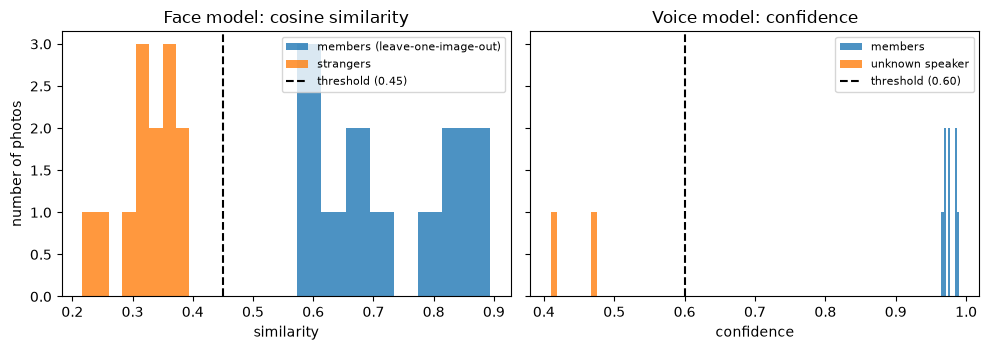

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)

ax = axes[0]
ax.hist(genuine, bins=8, alpha=0.8, label="members (leave-one-image-out)")
ax.hist(impostors.similarity, bins=8, alpha=0.8, label="strangers")
ax.axvline(threshold, color="black", ls="--", label=f"threshold ({threshold})")
ax.set_title("Face model: cosine similarity"); ax.set_xlabel("similarity"); ax.set_ylabel("number of photos"); ax.legend(fontsize=8)

ax = axes[1]
ax.hist(members_v.confidence, bins=8, alpha=0.8, label="members")
ax.hist(unknown_v.confidence, bins=8, alpha=0.8, label="unknown speaker")
thr = vv._load_bundle(vv.DEFAULT_MODEL_PATH)["threshold"]
ax.axvline(thr, color="black", ls="--", label=f"threshold ({thr:.2f})")
ax.set_title("Voice model: confidence"); ax.set_xlabel("confidence"); ax.legend(fontsize=8)

plt.tight_layout()
plt.show()